# Digits CNN Lab: experiment review

Recognize handwritten digits from 8×8 grayscale images while demonstrating the complete deep-learning experiment cycle: deterministic initialization, minibatch optimization, validation checkpointing, a classical baseline and visual error analysis.

This notebook inspects the committed experiment. Run `python -m digits_cnn train` from the repository root to regenerate the evidence. Raw datasets and local artifacts are not embedded here.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "reports/metrics.json").is_file():
    root = root.parent
report = json.loads((root / "reports/metrics.json").read_text())
print("Selected model:", report["selected"])
print("Split:", report["split"])
print("Recorded Python:", report["provenance"]["python"])

Selected model: cnn
Split: {'train': 1078, 'validation': 359, 'test': 360, 'method': 'stratified image split; writer IDs unavailable'}
Recorded Python: 3.11.14


## Compare held-out performance

Lower MAE/RMSE/log loss is better; higher F1, accuracy, recall and NDCG is better. The selected model was chosen before examining test outcomes.

In [2]:
comparison = pd.DataFrame(report["test"]).T
display(comparison)

,accuracy,macro_f1,log_loss
scaled_logistic,0.963889,0.963973,0.126339
cnn,0.986111,0.985817,0.059831


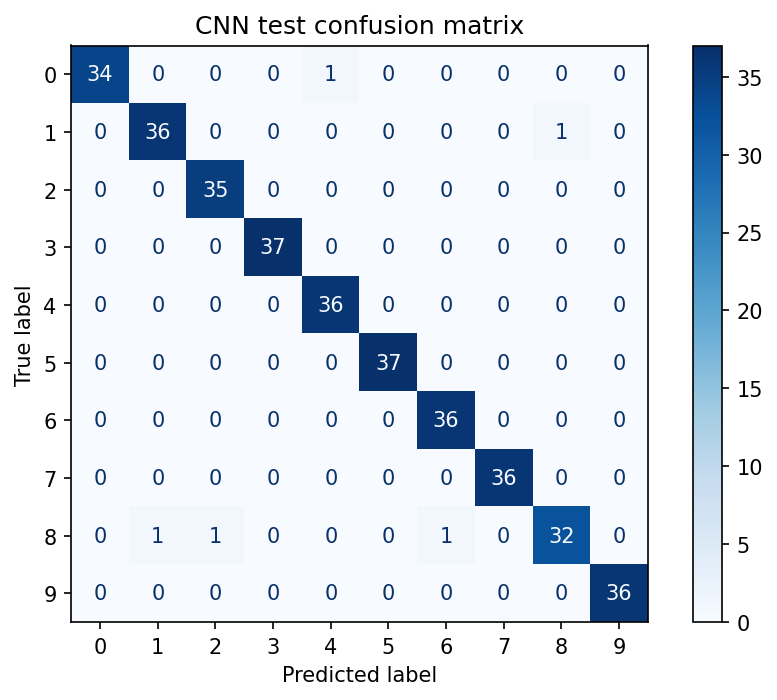

In [3]:
display(Image(filename=str(root / "reports/evaluation.png")))

## What the measurements mean

The restored CNN reaches 98.61% test accuracy versus 96.39% for logistic regression on this split. Five of 360 test images are wrong. Inspect the error gallery and learning curve before interpreting a headline accuracy. Softmax confidence is not calibrated, and a random image split does not measure performance on entirely unseen writers.

## Where they stop

Writer IDs are unavailable in the bundled subset, so writers can appear across partitions. The small images and curated preprocessing differ greatly from camera photos and scanned documents. There is no image upload or OCR pipeline. CPU determinism is requested, but different libraries, hardware or platforms can still produce small numeric differences. An all-zero input is schema-valid and can still get a confident prediction; out-of-distribution rejection is not implemented.